# Logistics Delivery Analysis and Visualization
### Week 3: Advanced Data Analysis and Visualization

**Dataset:** Delivery_Logistics_Cleaned.csv (25,000 deliveries, 14 columns), the cleaned data from Week 2
**Goal:** Explore the data, draw charts, and find what drives delays and cost.

## Step 1: Summary Statistics (Central Tendencies)

In [1]:
import pandas as pd

df = pd.read_csv("D:\\PROJECT\\Yuva Intern\\Dataset\\Delivery_Logistics_Cleaned.csv")

print("Rows and columns:", df.shape)
print()

columns = ["distance_km", "package_weight_kg", "delivery_time_hours",
           "expected_time_hours", "delivery_cost", "delivery_rating"]

summary = df[columns].agg(["mean", "median", "std", "min", "max"]).round(1)
print(summary)

Rows and columns: (25000, 14)

        distance_km  package_weight_kg  delivery_time_hours  \
mean          150.4               25.1                  6.2   
median        151.0               25.1                  6.0   
std            86.4               14.4                  3.1   
min             3.6                0.7                  0.0   
max           297.1               49.5                 19.0   

        expected_time_hours  delivery_cost  delivery_rating  
mean                   13.1          864.9              3.7  
median                  8.0          867.5              4.0  
std                     7.6          435.7              1.1  
min                     2.0           95.7              1.0  
max                    24.0         1632.7              5.0  


## Summary Statistics Result

| Column | Mean | Median | Std | Min | Max |
|---|---|---|---|---|---|
| distance_km | 150.4 | 151.0 | 86.4 | 3.6 | 297.1 |
| package_weight_kg | 25.1 | 25.1 | 14.4 | 0.7 | 49.5 |
| delivery_time_hours | 6.2 | 6.0 | 3.1 | 0 | 19 |
| expected_time_hours | 13.1 | 8.0 | 7.6 | 2 | 24 |
| delivery_cost | 864.9 | 867.5 | 435.7 | 95.7 | 1,632.7 |
| delivery_rating | 3.7 | 4.0 | 1.1 | 1 | 5 |

**Insight:**
- Distance, weight and cost have a mean very close to the median (for example, 150.4 vs 151.0 km), so their values are spread evenly with no heavy skew.
- Expected time has a mean of 13.1 hours but a median of only 8.0, so a group of deliveries with long expected times pulls the average up.
- The average delivery takes 6.2 hours against 13.1 expected, which looks fine on average but hides the 26.7% of deliveries that are still late. Averages alone are not enough, so the next steps compare groups.
- The average rating (3.7) is below the median (4.0), which means a number of low ratings pull the average down.

## Step 2: Distributions (Histograms)

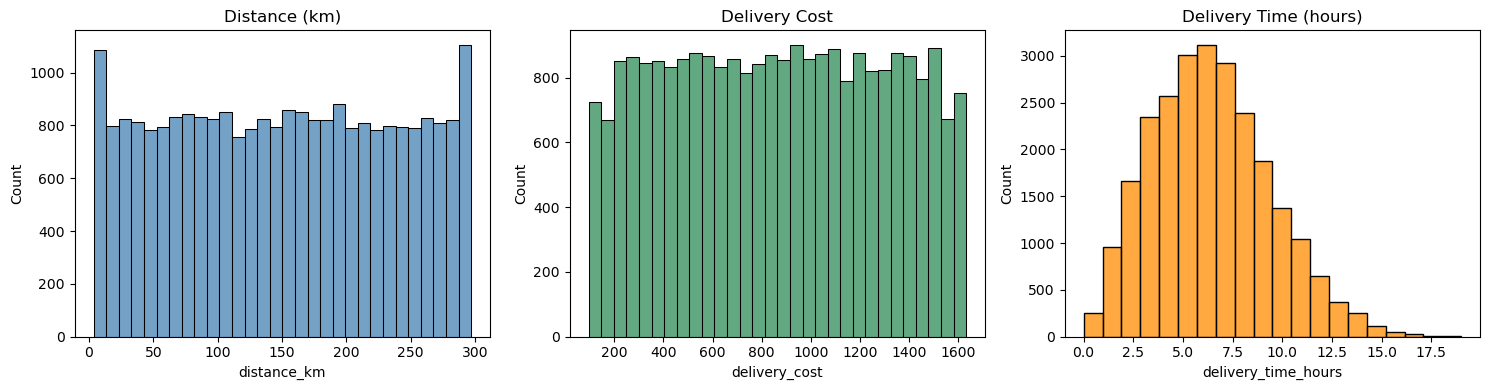

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["distance_km"], bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Distance (km)")

sns.histplot(df["delivery_cost"], bins=30, ax=axes[1], color="seagreen")
axes[1].set_title("Delivery Cost")

sns.histplot(df["delivery_time_hours"], bins=20, ax=axes[2], color="darkorange")
axes[2].set_title("Delivery Time (hours)")

plt.tight_layout()
plt.show()

## Distributions Result

**Why this chart:** A histogram shows how values are spread across ranges, which helps spot skew, gaps and unusual peaks in operational data.

| Variable | Shape | What it shows |
|---|---|---|
| Distance (km) | Almost flat, about 800 deliveries in most bars | Deliveries are spread evenly from 4 to 297 km, with slightly taller bars at the shortest and longest ends (about 1,100 each) |
| Delivery cost | Almost flat from about ₹200 to ₹1,550 | Costs are spread evenly, with fewer deliveries in the lowest and highest cost bars |
| Delivery time (hours) | Bell shape with a longer tail on the right | Most deliveries take 5 to 8 hours, the peak is at about 6 to 7 hours (about 3,100 deliveries), and a few take up to 19 hours |

**Insight:**
- Distance and cost have the same flat shape, which matches the earlier finding that cost is almost fully decided by distance (correlation 0.99).
- The company serves short, medium and long distances in similar numbers, so no single distance band dominates its workload.
- Delivery time is bunched around the 6-hour mark, but the right tail shows a small group of deliveries taking 12 to 19 hours. These slow deliveries are the first place to look for bottlenecks.

## Step 3: Actual vs Expected Time by Delivery Mode

               delivery_time_hours  expected_time_hours
delivery_mode                                          
express                        6.2                  4.5
same day                       6.2                  8.0
standard                       6.2                 24.0
two day                        6.3                 16.0


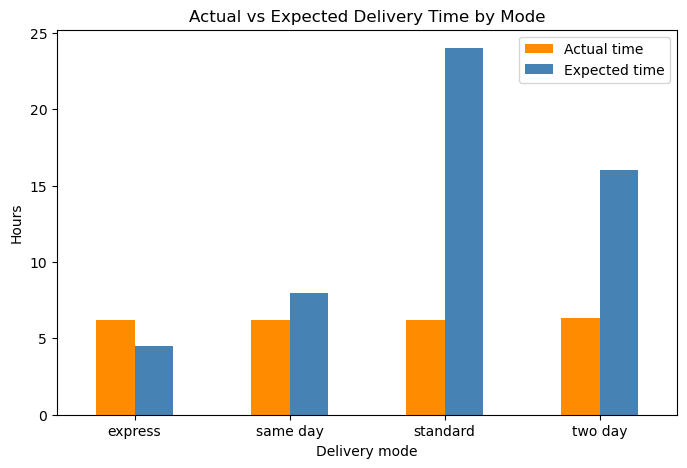

In [3]:
# Average actual and expected time for each delivery mode
time_by_mode = df.groupby("delivery_mode")[["delivery_time_hours", "expected_time_hours"]].mean().round(1)
print(time_by_mode)

time_by_mode.plot(kind="bar", figsize=(8, 5), color=["darkorange", "steelblue"])
plt.title("Actual vs Expected Delivery Time by Mode")
plt.ylabel("Hours")
plt.xlabel("Delivery mode")
plt.xticks(rotation=0)
plt.legend(["Actual time", "Expected time"])
plt.show()

## Actual vs Expected Time Result

**Why this chart:** A grouped bar chart puts two numbers side by side for each category, so the gap between what was promised and what was delivered is easy to see.

| Delivery mode | Actual time (hours) | Expected time (hours) | Gap |
|---|---|---|---|
| Express | 6.2 | 4.5 | 1.7 hours slower than promised |
| Same day | 6.2 | 8.0 | 1.8 hours faster than promised |
| Standard | 6.2 | 24.0 | 17.8 hours faster than promised |
| Two day | 6.3 | 16.0 | 9.7 hours faster than promised |

**Insight:**
- Every mode takes about 6.2 hours, so the "faster" modes are not actually faster. Only the promise is different.
- Express is the one mode where the actual time (6.2 hours) is longer than the promise (4.5 hours), which explains why 73.8% of express deliveries are late.
- Same day is faster than its promise on average (6.2 vs 8.0 hours), yet 32.5% are still late. This means some deliveries run much longer than the average, which matches the right tail seen in the histogram.
- Standard and two day have a very large buffer (17.8 and 9.7 hours), which is why they are almost never late.
- The bottleneck is mainly in how the promises are set, not in how fast the deliveries are made.

## Step 4: Correlation Heatmap

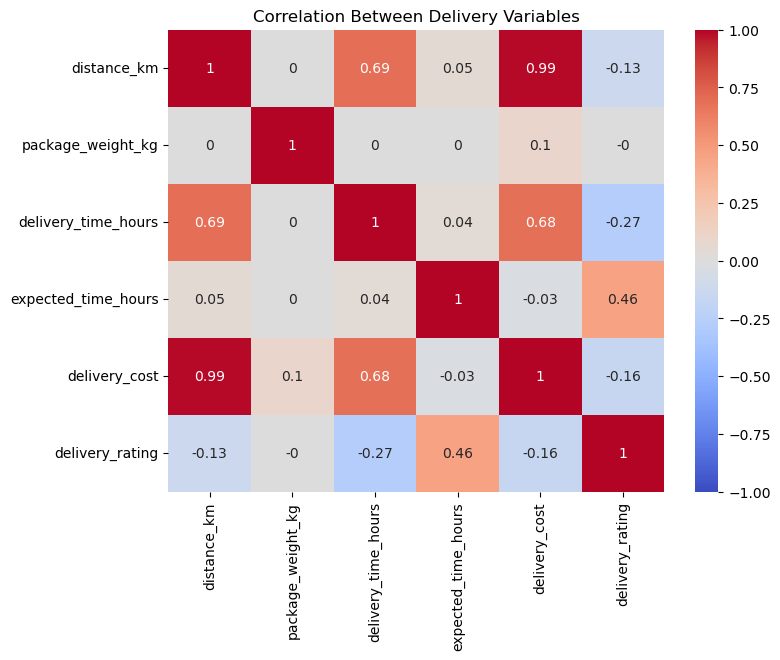

In [4]:
columns = ["distance_km", "package_weight_kg", "delivery_time_hours",
           "expected_time_hours", "delivery_cost", "delivery_rating"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[columns].corr().round(2), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Delivery Variables")
plt.show()

## Correlation Heatmap Result

**Why this chart:** A heatmap shows every pair of variables in one picture, so the strongest and weakest links can be spotted at a glance. The colors make strong links stand out, and the numbers give the exact values.

| Pair of variables | Correlation | Meaning |
|---|---|---|
| Distance and cost | 0.99 | Cost is almost fully decided by distance |
| Distance and delivery time | 0.69 | Longer distances take longer |
| Delivery time and cost | 0.68 | Slower deliveries cost more, mainly because they are also longer in distance |
| Expected time and rating | 0.46 | Deliveries with a longer promised time get higher ratings |
| Delivery time and rating | -0.27 | Slower deliveries get lower ratings |
| Weight and every other variable | 0.10 or less | Package weight has almost no effect |

**Insight:**
- Distance is the main driver of both cost (0.99) and delivery time (0.69), so route length is the first thing to manage.
- Weight has almost no link to cost (0.10) or time (0.00), so pricing by weight would not match how costs behave in this data.
- Customers rate deliveries higher when the promised time is longer (0.46), and lower when the real time is longer (-0.27). A likely reason is that deliveries with long promises are rarely late, though correlation alone does not prove this.
- Expected time and actual time are almost unrelated (0.04). Promises are not based on how long the delivery will really take, which supports the earlier finding that the bottleneck is in how promises are set.

## Step 5: Delay Rate by Weather and Vehicle Type

weather_condition
clear     17.4
cold      16.0
foggy     30.3
hot       17.1
rainy     37.4
stormy    41.4
Name: delayed, dtype: float64

vehicle_type
bike       27.0
ev bike    26.4
ev van     26.6
scooter    26.1
truck      27.0
van        26.8
Name: delayed, dtype: float64


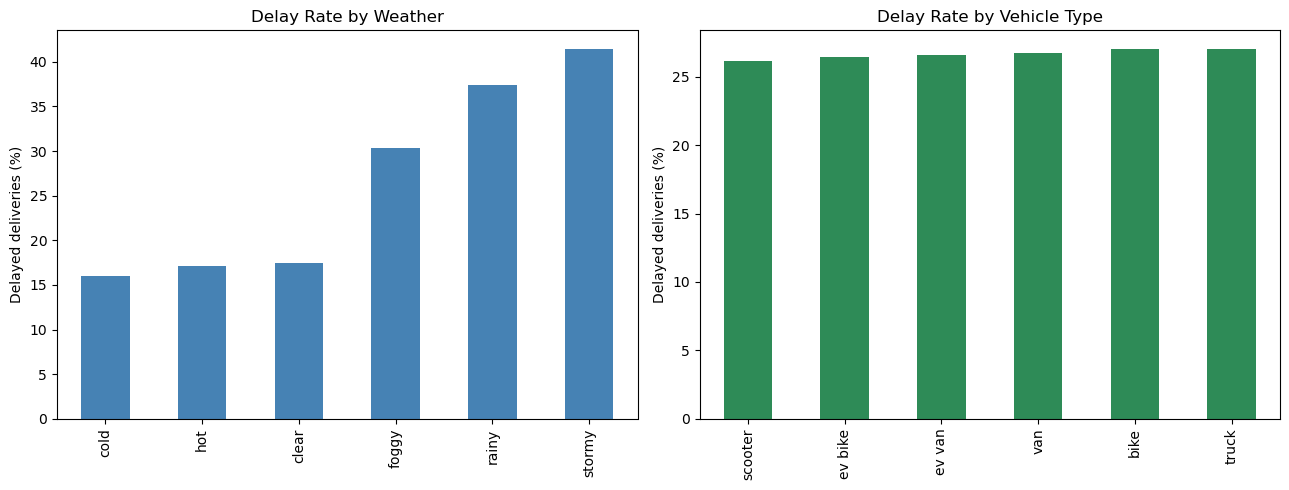

In [5]:
# Delay rate (%) by weather and by vehicle type
delay_weather = (df["delayed"] == "yes").groupby(df["weather_condition"]).mean() * 100
delay_vehicle = (df["delayed"] == "yes").groupby(df["vehicle_type"]).mean() * 100

print(delay_weather.round(1))
print()
print(delay_vehicle.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

delay_weather.sort_values().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Delay Rate by Weather")
axes[0].set_ylabel("Delayed deliveries (%)")
axes[0].set_xlabel("")

delay_vehicle.sort_values().plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Delay Rate by Vehicle Type")
axes[1].set_ylabel("Delayed deliveries (%)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

## Delay Rate by Weather and Vehicle Type Result

**Why this chart:** Bar charts compare one value across categories, and sorting the bars from lowest to highest makes the worst group easy to see.

| Weather | Delay rate | Vehicle type | Delay rate |
|---|---|---|---|
| Stormy | 41.4% | Bike | 27.0% |
| Rainy | 37.4% | Truck | 27.0% |
| Foggy | 30.3% | Van | 26.8% |
| Clear | 17.4% | EV van | 26.6% |
| Hot | 17.1% | EV bike | 26.4% |
| Cold | 16.0% | Scooter | 26.1% |

**Insight:**
- Stormy weather has a 41.4% delay rate, about 2.4 times the 17.4% in clear weather. Rainy (37.4%) and foggy (30.3%) are also well above clear weather.
- Hot and cold weather (17.1% and 16.0%) are about the same as clear weather, so the problem is bad visibility and wet roads, not temperature.
- Vehicle type makes almost no difference: all six types lie between 26.1% and 27.0%. Switching vehicles would not reduce delays.
- Weather is therefore a real cause of delays that the company can plan for, for example by adding extra time to promises on stormy and rainy days.

## Step 6: Delay Rate by Weather and Delivery Mode

delivery_mode      express  same day  standard  two day
weather_condition                                      
clear                 51.6      16.5       0.0      0.0
cold                  52.9      11.8       0.0      0.0
foggy                 89.3      34.8       0.0      0.1
hot                   52.0      15.1       0.0      0.0
rainy                 97.7      52.4       0.0      0.3
stormy                99.8      65.6       0.0      2.1


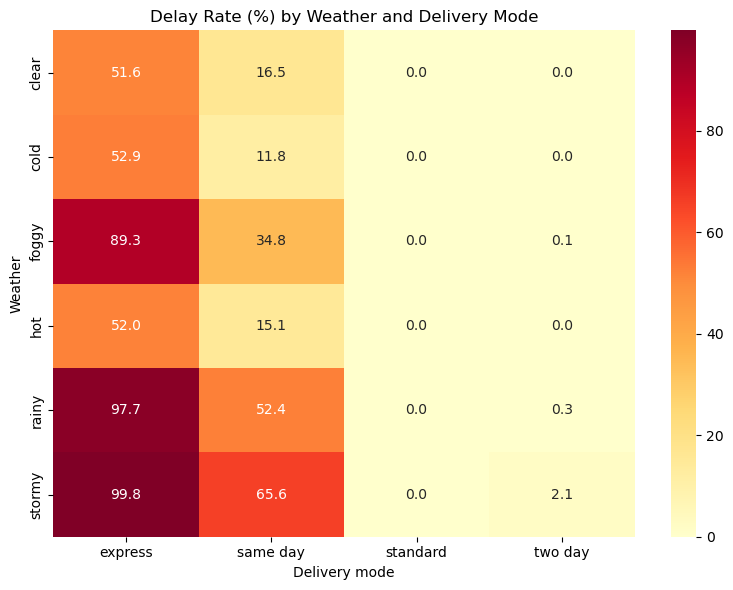

In [6]:
# Delay rate (%) for each weather and delivery mode combination
delay_table = (df["delayed"] == "yes").groupby(
    [df["weather_condition"], df["delivery_mode"]]
).mean().unstack() * 100

print(delay_table.round(1))

plt.figure(figsize=(8, 6))
sns.heatmap(delay_table, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Delay Rate (%) by Weather and Delivery Mode")
plt.ylabel("Weather")
plt.xlabel("Delivery mode")
plt.tight_layout()
plt.show()

## Delay Rate by Weather and Delivery Mode Result

**Why this chart:** A heatmap shows the effect of two factors together. Weather is on the rows and delivery mode is on the columns, and the color shows where delays are worst, so the hot spots can be seen at once.

| Weather | Express | Same day | Standard | Two day |
|---|---|---|---|---|
| Clear | 51.6% | 16.5% | 0.0% | 0.0% |
| Cold | 52.9% | 11.8% | 0.0% | 0.0% |
| Foggy | 89.3% | 34.8% | 0.0% | 0.1% |
| Hot | 52.0% | 15.1% | 0.0% | 0.0% |
| Rainy | 97.7% | 52.4% | 0.0% | 0.3% |
| Stormy | 99.8% | 65.6% | 0.0% | 2.1% |

**Insight:**
- Express deliveries are late 51.6% of the time even in clear weather. Weather makes it worse (97.7% in rain and 99.8% in storms), but the base problem is the short promised time of 4.5 hours.
- Same day deliveries are the most weather-sensitive:

## Step 7: Customer Rating by Delivery Status

                 mean  count
delivery_status             
delayed          2.40   5341
delivered        4.21  18331
failed           1.31   1328


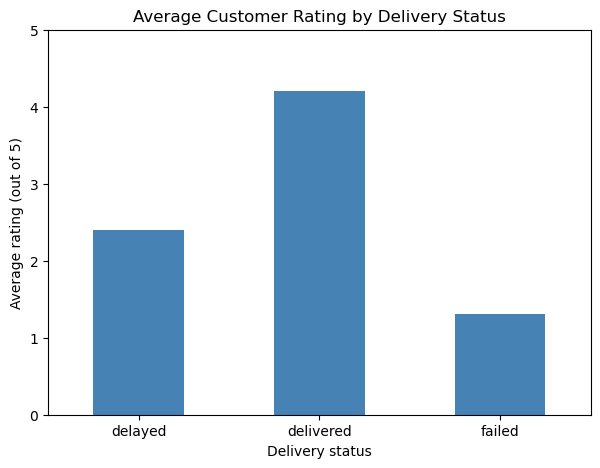

In [7]:
# Average rating and number of deliveries for each delivery status
rating_by_status = df.groupby("delivery_status")["delivery_rating"].agg(["mean", "count"]).round(2)
print(rating_by_status)

rating_by_status["mean"].plot(kind="bar", figsize=(7, 5), color="steelblue")
plt.title("Average Customer Rating by Delivery Status")
plt.ylabel("Average rating (out of 5)")
plt.xlabel("Delivery status")
plt.xticks(rotation=0)
plt.ylim(0, 5)
plt.show()

## Customer Rating by Delivery Status Result

**Why this chart:** A bar chart compares one average across a few categories. The axis runs from 0 to 5, so the real size of the gap between the groups is not exaggerated.

| Delivery status | Average rating | Number of deliveries | Share of all deliveries |
|---|---|---|---|
| Delivered (on time) | 4.21 | 18,331 | 73.3% |
| Delayed | 2.40 | 5,341 | 21.4% |
| Failed | 1.31 | 1,328 | 5.3% |

**Insight:**
- A delayed delivery loses 1.81 rating points compared with an on-time one (4.21 down to 2.40), and a failed delivery loses 2.90 points (down to 1.31).
- Together, delayed and failed deliveries make up 6,669 of 25,000 deliveries (26.7%). This matches the delay rate found in Week 1, which suggests that failed deliveries are also counted as delayed in the data.
- Because the average rating is 3.7 overall, the 26.7% of unhappy customers are what keeps it from reaching the 4.21 that on-time deliveries get.
- Fixing delays, especially for express and same day deliveries in bad weather, is the most direct way to raise customer satisfaction.

## Step 8: Delay Rate by Delivery Partner and Region

delivery_partner
delhivery           24.8
fedex               25.2
dhl                 26.3
ecom express        26.6
blue dart           26.9
amazon logistics    27.2
shadowfax           27.3
ekart               27.4
xpressbees          28.3
Name: delayed, dtype: float64

region
east       25.8
north      26.6
south      26.8
west       26.9
central    27.3
Name: delayed, dtype: float64


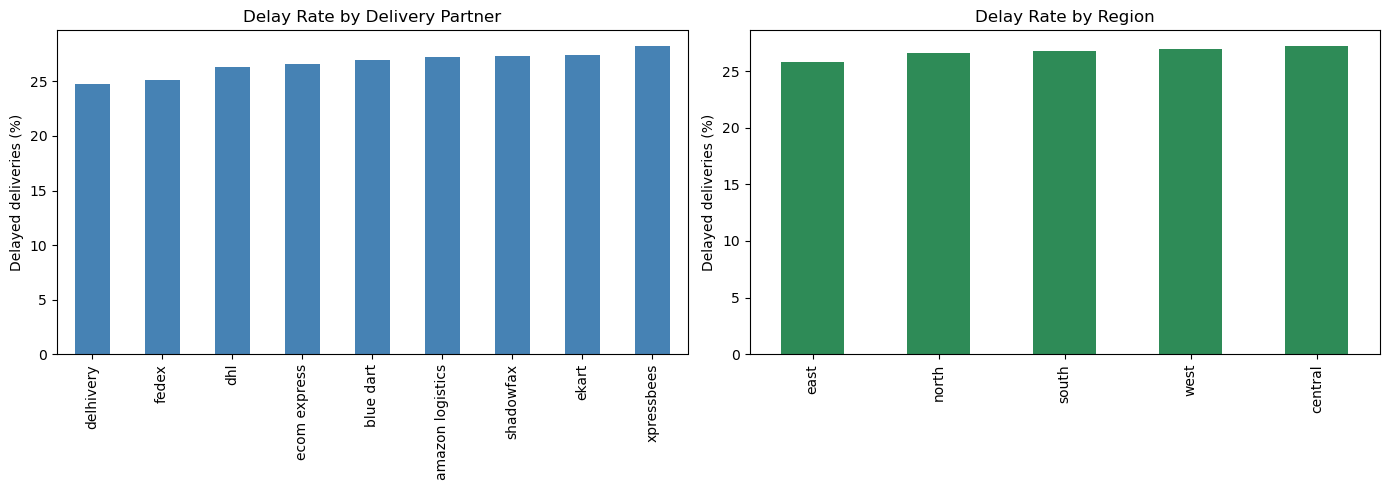

In [8]:
# Delay rate (%) by delivery partner and by region
delay_partner = (df["delayed"] == "yes").groupby(df["delivery_partner"]).mean() * 100
delay_region = (df["delayed"] == "yes").groupby(df["region"]).mean() * 100

print(delay_partner.round(1).sort_values())
print()
print(delay_region.round(1).sort_values())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

delay_partner.sort_values().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Delay Rate by Delivery Partner")
axes[0].set_ylabel("Delayed deliveries (%)")
axes[0].set_xlabel("")

delay_region.sort_values().plot(kind="bar", ax=axes[1], color="seagreen")
axes[1].set_title("Delay Rate by Region")
axes[1].set_ylabel("Delayed deliveries (%)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

## Delay Rate by Delivery Partner and Region Result

**Why this chart:** Bar charts sorted from lowest to highest make it easy to see whether one group stands out. Using the same style as the other charts keeps the comparison fair.

| Delivery partner | Delay rate | Region | Delay rate |
|---|---|---|---|
| Delhivery | 24.8% | East | 25.8% |
| FedEx | 25.2% | North | 26.6% |
| DHL | 26.3% | South | 26.8% |
| Ecom Express | 26.6% | West | 26.9% |
| Blue Dart | 26.9% | Central | 27.3% |
| Amazon Logistics | 27.2% | | |
| Shadowfax | 27.3% | | |
| Ekart | 27.4% | | |
| XpressBees | 28.3% | | |

**Insight:**
- The nine partners lie between 24.8% and 28.3%, a gap of only 3.5 percentage points. The five regions lie between 25.8% and 27.3%, a gap of only 1.5 points.
- Compare this with weather (16.0% to 41.4%) and delivery mode (0.0% to 73.8%), where the gaps are far larger. Partner and region are minor factors in this data.
- Delhivery and FedEx have the lowest delay rates, and XpressBees has the highest, but the differences are small. Changing partners or focusing on one region would not fix the delay problem.
- The delays come mainly from how promises are set (delivery mode) and from bad weather, which the company can plan for.